# FFSM++ Oracle paper output parser #

### Header ###

In [108]:
import sys          # only needed to determine Python version number
import pandas as pd
import numpy as np
from pandas import DataFrame, Series
import output_parser_lib as parserlib

# Matplotlib options
import matplotlib.pyplot as plt
import matplotlib   # only needed to determine Matplotlib version number
# Render plots inline:
%matplotlib inline  
pd.set_option('display.mpl_style', 'default') # Make the graphs a bit prettier
plt.rcParams['figure.figsize'] = (15, 5)

pd.set_option('display.max_rows', 25)


### Global variables ###

In [36]:
scenarios = ['constant', 'constant_nomgm', 'constant_nora', 'constant_carea', 'arpege_a1b', 'arpege_a1b_carea', 'arpege_a1b_noexp', 'arpege_a1b_fullexp', 'arpege_a1b_nora', 'arpege_a1b_nomgm', 'arpege_a1b_nopr', 'arpege_a1b_noph', 'arpege_a2', 'arpege_b1', 'CNCM33_1', 'DMIEH5C_1', 'DMIEH5C_2', 'DMIEH5C_3', 'EGMAM2_3', 'HADGEM2_1', 'IPCM4_1', 'IPCM4_2', 'IPCM4_3', 'MPEH5C_1', 'MPEH5C_2', 'MPEH5C_3']
scenarios_a1b = ['arpege_a1b', 'CNCM33_1', 'DMIEH5C_1', 'DMIEH5C_2', 'DMIEH5C_3', 'EGMAM2_3', 'HADGEM2_1', 'IPCM4_1', 'IPCM4_2', 'IPCM4_3', 'MPEH5C_1', 'MPEH5C_2', 'MPEH5C_3']
#scenarios = ['constant']

baseIDir = 'results'
regions_map = {11042: 'Alsace', 11061: 'Aquitaine', 11072: 'Auvergne', 11025: 'Basse-Normandie', 11026: 'Bourgogne',
    11052: 'Bretagne', 11024: 'Centre', 11021: 'Champagne-Ardenne', 11083: 'Corse', 11043: 'Franche-Comté',
    11023: 'Haute-Normandie', 11010: 'Île de France', 11081: 'Languedoc-Roussillon', 11063: 'Limousin',
    11041: 'Lorraine', 11062: 'Midi-Pyrénées', 11030: 'Nord - Pas-de-Calais', 11051: 'Pays de la Loire',
    11022: 'Picardie', 11053: 'Poitou-Charentes', 11082: 'Provence-Alpes-Côte d\'Azur', 11071: 'Rhône-Alpes'} 
products_map = {'hardWRoundW': 'Hardwood Roundwood', 'softWRoundW': 'Softwood Roundwood',
                'pulpWFuelW': 'Pulpwood and Fuelwood', 'fuelW': 'Fuelwood', 'hardWSawnW': 'Hardwood Sawnwood',
                'softWSawnW': 'Softwood Sawnwood', 'plyW': 'Plywood', 'pulpW': 'Pulpwood', 'pannels': 'Pannels'}

# sigma – prix elasticity (supply and demand)
sigma_map = {'hardWRoundW': 1.2, 'softWRoundW': 0.9, 'pulpWFuelW': 0.9, 'fuelW': -0.6, 'hardWSawnW': -0.5,
             'softWSawnW': -0.4, 'plyW': -0.3, 'pannels': -0.5, 'pulpW': -0.5}
gamma = 0.5
trs   = 0.5




### Definition of helper functions ##

In [37]:
def form1(x):
    return "{:0,.0f}".format(x)  # e.g. 1234567.89 --> 1,234,567
def form2(x):
    return "{:0,.2f}".format(x)  # e.g. 1234567.89 --> 1,234,567.89

### Data import ###
(may take long time)

In [38]:
forestData_byscenario = [pd.read_csv(baseIDir+'/forestData_'+scenario+'.csv',sep=';',  dtype={'value': np.float64}) for scenario in scenarios]
forestDataReg = pd.concat(forestData_byscenario)
forestDataReg = forestDataReg.drop(['Unnamed: 8'],axis=1) # we don't want this column never
forestDataReg = forestDataReg.drop(['country'],axis=1) # we don't want this column never
productData_byscenario = [pd.read_csv(baseIDir+'/productData_'+scenario+'.csv',sep=';',  dtype={'value': np.float64}) for scenario in scenarios]
productDataReg = pd.concat(productData_byscenario)
productDataReg = productDataReg.drop(['Unnamed: 8'],axis=1) # we don't want this column never
productDataReg = productDataReg.drop(['country'],axis=1) # we don't want this column never
carbonData_byscenario = [pd.read_csv(baseIDir+'/carbonBalance_'+scenario+'.csv',sep=';',  dtype={'value': np.float64}) for scenario in scenarios]
carbonDataReg = pd.concat(carbonData_byscenario)
carbonDataReg = carbonDataReg.drop(['Unnamed: 6'],axis=1) # we don't want this column never
carbonDataReg = carbonDataReg.drop(['country'],axis=1) # we don't want this column never

### Common data tidying ###

In [39]:
forestDataReg['spGroup'] = np.where(forestDataReg['forType'].isin(['broadL_highF', 'broadL_mixedF','broadL_copp','ash']), 'broadleaved', 'coniferous')
#forestDataReg.replace({'region': regions_map}, inplace=True)
#productDataReg.replace({'region': regions_map}, inplace=True)
productDataReg['prodLev'] = np.where(productDataReg['prod'].isin(['hardWRoundW', 'softWRoundW', 'pulpWFuelW','ashRoundW']), 'priProd', 'secProd')

### Ecological - ecosystem services dimension ###

#### Area of total forest by region:  table now and 2100 (just to report regions with maximum variations) ####
Unit: ha

In [109]:
# creating tables forArea_total_arpege_a1b and forArea_total_a1b
forArea = forestDataReg[forestDataReg['parName'] == 'forArea'].copy()
forArea.replace({'region': regions_map}, inplace=True) # doesn't work on index, only on a column
forArea = forArea.drop(['freeDim','parName','forType'],axis=1) # we don't want these columns never
forArea_byGroup = forArea.groupby(['scen','region','year','spGroup'], as_index=False).agg(np.sum)
forArea_total = forArea.groupby(['scen','region','year'], as_index=False).agg(np.sum)
forArea_total = forArea_total[forArea_total['year'].isin([2015,2100])]
forArea_total_arpege_a1b = forArea_total[forArea_total['scen'] == 'arpege_a1b']
forArea_total_arpege_a1b = forArea_total_arpege_a1b.drop(['scen'], axis=1)
forArea_total_arpege_a1b.set_index(['region','year'], inplace=True)
forArea_total_arpege_a1b = forArea_total_arpege_a1b.unstack(['year'])
forArea_total_arpege_a1b.columns = forArea_total_arpege_a1b.columns.droplevel() # DROP TOP COLUMN LEVEL

forArea_total_arpege_a1b['diff'] = forArea_total_arpege_a1b[2100]-forArea_total_arpege_a1b[2015]
forArea_total_arpege_a1b.loc['France'] = forArea_total_arpege_a1b.sum()

forArea_total_a1b = forArea_total[forArea_total['scen'].isin(scenarios_a1b)]
forArea_total_a1b = forArea_total_a1b.groupby(['region','year']).agg(np.mean)
forArea_total_a1b = forArea_total_a1b.unstack(['year'])
forArea_total_a1b.columns = forArea_total_a1b.columns.droplevel() # DROP TOP COLUMN LEVEL

forArea_total_a1b['diff'] = forArea_total_a1b[2100]-forArea_total_a1b[2015]

forArea_total_a1b.loc['France'] = forArea_total_a1b.sum()
forArea_total_a1b_Mha = forArea_total_a1b/1000000
forArea_total_a1b_Mha['diff_pc'] = 100*forArea_total_a1b_Mha['diff']/forArea_total_a1b_Mha[2015]
forArea_total_a1b_Mha

#print (forArea_total_a1b.to_latex(formatters=[form1, form1, form1]))


year,2015,2100,diff,diff_pc
region,,,,
Alsace,0.313517,0.298958,-0.014559,-4.643880
Aquitaine,1.532109,1.491478,-0.040632,-2.652001
Auvergne,0.734735,0.717509,-0.017226,-2.344579
Basse-Normandie,0.140962,0.127682,-0.013280,-9.421127
Bourgogne,0.932854,0.883781,-0.049073,-5.260569
Bretagne,0.274563,0.252028,-0.022535,-8.207594
Centre,0.850686,0.802033,-0.048653,-5.719313
Champagne-Ardenne,0.651349,0.577461,-0.073889,-11.343923
Corse,0.258457,0.274703,0.016246,6.285734


#### Share of broadleaved/coniferous:  table now/2100 by region ####

In [74]:
forArea_byGroup_a1b = forArea_byGroup[forArea_byGroup['scen'].isin(scenarios_a1b)]
forArea_byGroup_a1b = forArea_byGroup_a1b[forArea_byGroup_a1b['year'].isin([2015,2100])]
forArea_byGroup_a1b = forArea_byGroup_a1b.groupby(['region','year','spGroup']).agg(np.mean)
forArea_byGroup_a1b

value
region                     year spGroup                   
Alsace                     2015 broadleaved  194377.934615
                                coniferous   119139.384615
                           2100 broadleaved  184779.183077
                                coniferous   114178.769231
Aquitaine                  2015 broadleaved  733025.792308
                                coniferous   799083.692308
                           2100 broadleaved  878138.923077
                                coniferous   613339.000000
Auvergne                   2015 broadleaved  387465.178462
                                coniferous   347270.000000
...                                                    ...
Provence-Alpes-Côte d'Azur 2100 broadleaved  564970.076923
                                coniferous   570686.846154
Rhône-Alpes                2015 broadleaved  876197.338462
                                coniferous   739980.230769
                           2100 broadleaved  930003.753846
                                coniferous   734247.769231
Île de France              2015 broadleaved  249195.307692
                                coniferous    20326.107692
                           2100 broadleaved  196658.761538
                                coniferous    47292.476923

[88 rows x 1 columns]

In [110]:
#forArea_byGroup_arpege_a1b = forArea_byGroup[forArea_byGroup['scen'] == 'arpege_a1b']
#forArea_byGroup_arpege_a1b = forArea_byGroup_arpege_a1b.drop(['scen'], axis=1)
#forArea_byGroup_arpege_a1b = forArea_byGroup_arpege_a1b[forArea_byGroup_arpege_a1b['year'].isin([2015,2100])]
#forArea_byGroup_arpege_a1b.set_index(['region','year','spGroup'], inplace=True)
#forArea_byGroup_arpege_a1b=forArea_byGroup_arpege_a1b.unstack(['year','spGroup'])
#forArea_byGroup_arpege_a1b.columns = forArea_byGroup_arpege_a1b.columns.droplevel() # DROP TOP COLUMN LEVEL
#forArea_byGroup_arpege_a1b.columns.set_levels([ [2015, 2100], ['br', 'con']], inplace=True)
#forArea_byGroup_arpege_a1b.loc['France'] = forArea_byGroup_arpege_a1b.sum()
#forArea_byGroup_arpege_a1b[2015,'Broadleaved'] = 100 * forArea_byGroup_arpege_a1b[2015,'br'] / (forArea_byGroup_arpege_a1b[2015,'br']+forArea_byGroup_arpege_a1b[2015,'con']) 
#forArea_byGroup_arpege_a1b[2015,'Coniferous'] = 100 * forArea_byGroup_arpege_a1b[2015,'con'] / (forArea_byGroup_arpege_a1b[2015,'br']+forArea_byGroup_arpege_a1b[2015,'con']) 
#forArea_byGroup_arpege_a1b[2100,'Broadleaved'] = 100 * forArea_byGroup_arpege_a1b[2100,'br'] / (forArea_byGroup_arpege_a1b[2100,'br']+forArea_byGroup_arpege_a1b[2100,'con']) 
#forArea_byGroup_arpege_a1b[2100,'Coniferous'] = 100 * forArea_byGroup_arpege_a1b[2100,'con'] / (forArea_byGroup_arpege_a1b[2100,'br']+forArea_byGroup_arpege_a1b[2100,'con']) 
#forArea_byGroup_arpege_a1b.drop([(2015,'br'),(2015,'con'),(2100,'br'),(2100,'con')], axis=1, inplace=True)
#forArea_byGroup_arpege_a1b
#print (forArea_byGroup_arpege_a1b.to_latex(formatters=[form2, form2, form2, form2]))

forArea_byGroup_a1b = forArea_byGroup[forArea_byGroup['scen'].isin(scenarios_a1b)]
forArea_byGroup_a1b = forArea_byGroup_a1b[forArea_byGroup_a1b['year'].isin([2015,2100])]
forArea_byGroup_a1b = forArea_byGroup_a1b.groupby(['region','year','spGroup']).agg(np.mean)
forArea_byGroup_a1b = forArea_byGroup_a1b.unstack(['year','spGroup'])
forArea_byGroup_a1b.columns = forArea_byGroup_a1b.columns.droplevel() # DROP TOP COLUMN LEVEL
forArea_byGroup_a1b.columns.set_levels([ [2015, 2100], ['br', 'con']], inplace=True)
forArea_byGroup_a1b.loc['France'] = forArea_byGroup_a1b.sum()
forArea_byGroup_a1b
forAreaShare_byGroup_a1b = forArea_byGroup_a1b.copy()
forAreaShare_byGroup_a1b[2015,'Broadleaved'] = 100 * forArea_byGroup_a1b[2015,'br']  / (forArea_byGroup_a1b[2015,'br']+forArea_byGroup_a1b[2015,'con']) 
forAreaShare_byGroup_a1b[2015,'Coniferous']  = 100 * forArea_byGroup_a1b[2015,'con'] / (forArea_byGroup_a1b[2015,'br']+forArea_byGroup_a1b[2015,'con']) 
forAreaShare_byGroup_a1b[2100,'Broadleaved'] = 100 * forArea_byGroup_a1b[2100,'br']  / (forArea_byGroup_a1b[2100,'br']+forArea_byGroup_a1b[2100,'con']) 
forAreaShare_byGroup_a1b[2100,'Coniferous']  = 100 * forArea_byGroup_a1b[2100,'con'] / (forArea_byGroup_a1b[2100,'br']+forArea_byGroup_a1b[2100,'con']) 
forAreaShare_byGroup_a1b.drop([(2015,'br'),(2015,'con'),(2100,'br'),(2100,'con')], axis=1, inplace=True)
forAreaShare_byGroup_a1b
#print (forArea_byGroup_a1b.to_latex(formatters=[form2, form2, form2, form2]))


year                              2015                   2100           
spGroup                    Broadleaved Coniferous Broadleaved Coniferous
region                                                                  
Alsace                       61.999106  38.000894   61.807750  38.192250
Aquitaine                    47.844217  52.155783   58.877098  41.122902
Auvergne                     52.735351  47.264649   57.538839  42.461161
Basse-Normandie              81.907703  18.092297   77.091238  22.908762
Bourgogne                    89.108868  10.891132   88.423194  11.576806
Bretagne                     69.436113  30.563887   70.643162  29.356838
Centre                       86.488993  13.511007   82.313857  17.686143
Champagne-Ardenne            91.074524   8.925476   84.138218  15.861782
Corse                        79.992003  20.007997   81.830920  18.169080
Franche-Comté                75.059162  24.940838   76.116101  23.883899
Haute-Normandie              90.416042   9.583958   90.177222   9.822778
Languedoc-Roussillon         63.833881  36.166119   65.162646  34.837354
Limousin                     68.293027  31.706973   68.309553  31.690447
Lorraine                     74.933579  25.066421   71.020760  28.979240
Midi-Pyrénées                87.476471  12.523529   84.364985  15.635015
Nord - Pas-de-Calais         96.953139   3.046861   97.460608   2.539392
Pays de la Loire             68.277524  31.722476   63.028874  36.971126
Picardie                     95.784104   4.215896   90.774731   9.225269
Poitou-Charentes             85.348884  14.651116   75.752525  24.247475
Provence-Alpes-Côte d'Azur   41.592013  58.407987   49.748306  50.251694
Rhône-Alpes                  54.214175  45.785825   55.881202  44.118798
Île de France                92.458444   7.541556   80.613963  19.386037
France                       69.417697  30.582303   69.669413  30.330587

#### Vol/ha of forest: map now/2100 by pixel, table now/2100 by region ####
vol unit: Mm^3, area unit: ha, v/ha unit: m^3/ha    

In [115]:
# (1/2) 
forVol = forestDataReg[forestDataReg['parName'] == 'vol'].copy()
forVol.replace({'region': regions_map}, inplace=True) # doesn't work on index, only on a column
forVol.drop(['freeDim','parName','forType'],axis=1, inplace=True) # we don't want these columns never
forVol_byGroup = forVol.groupby(['scen','region','year','spGroup'], as_index=False).agg(np.sum)
forVol_total = forVol.groupby(['scen','region','year'], as_index=False).agg(np.sum)
forVol_total = forVol_total[forVol_total['year'].isin([2015,2100])]

forVol_total_arpege_a1b = forVol_total[forVol_total['scen'] == 'arpege_a1b']
forVol_total_arpege_a1b = forVol_total_arpege_a1b.drop(['scen'], axis=1)
forVol_total_arpege_a1b.set_index(['region','year'], inplace=True)
forVol_total_arpege_a1b = forVol_total_arpege_a1b.unstack(['year'])
forVol_total_arpege_a1b.columns = forVol_total_arpege_a1b.columns.droplevel() # DROP TOP COLUMN LEVEL
forVol_total_arpege_a1b['diff'] = forVol_total_arpege_a1b[2100]-forVol_total_arpege_a1b[2015]
forVol_total_arpege_a1b.loc['France'] = forVol_total_arpege_a1b.sum()
forVol_total_arpege_a1b

forVol_total_a1b = forVol_total[forVol_total['scen'].isin(scenarios_a1b)]
forVol_total_a1b = forVol_total_a1b.groupby(['region','year']).agg(np.mean)
forVol_total_a1b = forVol_total_a1b.unstack(['year'])
forVol_total_a1b.columns = forVol_total_a1b.columns.droplevel() # DROP TOP COLUMN LEVEL
forVol_total_a1b['diff'] = forVol_total_a1b[2100]-forVol_total_a1b[2015]
forVol_total_a1b.loc['France'] = forVol_total_a1b.sum()
forVol_total_a1b['diff_pc'] = 100*forVol_total_a1b['diff']/forVol_total_a1b[2015]
forVol_total_a1b

year,2015,2100,diff,diff_pc
region,,,,
Alsace,90.141152,210.881660,120.740508,133.946046
Aquitaine,334.227454,615.041154,280.813700,84.018741
Auvergne,205.431432,419.721031,214.289598,104.311982
Basse-Normandie,35.107366,31.421692,-3.685674,-10.498292
Bourgogne,222.412099,461.211808,238.799708,107.368128
Bretagne,82.911446,172.723269,89.811823,108.322587
Centre,191.314400,425.786692,234.472292,122.558622
Champagne-Ardenne,147.891249,173.940262,26.049013,17.613627
Corse,38.025088,78.792969,40.767881,107.213112


In [117]:
# (2/2)
tempVol = forVol_total_a1b.copy()
tempVol.drop('diff_pc', axis=1, inplace=True)
columnIdx = pd.MultiIndex.from_tuples([('vol',2015),('vol',2100),('vol','diff')], names=['var', 'year'])                       
tempVol.columns=columnIdx  
tempArea =forArea_total_a1b.copy()
columnIdx = pd.MultiIndex.from_tuples([('area',2015),('area',2100),('area','diff')], names=['var', 'year'])                       
tempArea.columns=columnIdx  
forVolOverArea_total_a1b = pd.concat([tempVol,tempArea], axis=1)
forVolOverArea_total_a1b['v/ha',2015]= 1000000*forVolOverArea_total_a1b['vol',2015] / forVolOverArea_total_a1b['area',2015] 
forVolOverArea_total_a1b['v/ha',2100]= 1000000*forVolOverArea_total_a1b['vol',2100] / forVolOverArea_total_a1b['area',2100] 
forVolOverArea_total_a1b['diff_pc',2100] = 100*(forVolOverArea_total_a1b['v/ha',2100]-forVolOverArea_total_a1b['v/ha',2015])/forVolOverArea_total_a1b['v/ha',2015]
forVolOverArea_total_a1b.drop([('vol',2015),('vol',2100),('vol','diff'),('area',2015),('area',2100),('area','diff')], axis=1, inplace=True)
forVolOverArea_total_a1b
#print (forVolOverArea_total_arpege_a1b.to_latex(formatters=[form2, form2]))

var                               v/ha                 diff_pc
year                              2015        2100        2100
region                                                        
Alsace                      287.515700  705.389030  145.339308
Aquitaine                   218.148544  412.370270   89.031869
Auvergne                    279.599287  584.969928  109.217246
Basse-Normandie             249.056011  246.094234   -1.189201
Bourgogne                   238.421063  521.862217  118.882598
Bretagne                    301.975849  685.333274  126.949697
Centre                      224.894292  530.884587  136.059609
Champagne-Ardenne           227.053622  301.215676   32.662793
Corse                       147.123286  286.829407   94.958537
Franche-Comté               259.227809  567.126746  118.775427
Haute-Normandie             235.918829  307.875368   30.500549
Languedoc-Roussillon        132.232143  169.747523   28.370847
Limousin                    244.411267  310.440815   27.015755
Lorraine                    272.530325  506.561428   85.873417
Midi-Pyrénées               197.041986  573.578949  191.094786
Nord - Pas-de-Calais        302.113878  717.419106  137.466452
Pays de la Loire            267.155078  499.671126   87.034111
Picardie                    187.048491   73.966061  -60.456211
Poitou-Charentes            198.310220  393.901557   98.628975
Provence-Alpes-Côte d'Azur  143.384519  190.464963   32.835096
Rhône-Alpes                 233.055394  588.710847  152.605544
Île de France               189.091970  230.292690   21.788720
France                      220.551375  439.058241   99.073001

## Forest owners dimension ##
#### Forest expected returns: by region now and 2100. ####

In [122]:
#forestDataReg
#scen 	parName 	region 	forType 	freeDim 	year 	value 	spGroup
#expReturns = forestDataReg[(forestDataReg['parName'] == 'expReturns') & (forestDataReg['forType'].isnull())].copy() # don't like and
expReturns = forestDataReg[(forestDataReg['parName'] == 'expReturns')].copy() 
expReturns.replace({'region': regions_map}, inplace=True) # doesn't work on index, only on a column
expReturns_tot = expReturns[(expReturns['forType'].isnull()) & (expReturns['year'].isin([2015,2100]))]
expReturns_tot_a1b = expReturns_tot[expReturns_tot['scen'].isin(scenarios_a1b)]
expReturns_tot_a1b = expReturns_tot_a1b.drop(['freeDim','parName','forType','spGroup'],axis=1) # we don't want these columns never
expReturns_tot_a1b = expReturns_tot_a1b.groupby(['region','year']).agg(np.mean)
expReturns_tot_a1b = expReturns_tot_a1b.unstack(['year'])                   
expReturns_tot_a1b.columns=pd.MultiIndex.from_tuples([('expReturns',2015),('expReturns',2100)], names=['var', 'year']) 
expReturns_tot_a1b.loc['France'] = expReturns_tot_a1b.sum()
tempArea =forArea_total_a1b.copy()                    
tempArea.columns=pd.MultiIndex.from_tuples([('area',2015),('area',2100),('area','diff')], names=['var', 'year'])  
expReturns_tot_a1b = pd.concat([expReturns_tot_a1b,tempArea], axis=1)
expReturns_tot_a1b['sumExpReturns',2015] = expReturns_tot_a1b['expReturns',2015]*expReturns_tot_a1b['area',2015]
expReturns_tot_a1b['sumExpReturns',2100] = expReturns_tot_a1b['expReturns',2100]*expReturns_tot_a1b['area',2100]
expReturns_tot_a1b.drop('France',inplace=True)
expReturns_tot_a1b.loc['France'] = expReturns_tot_a1b.sum() # if I do not drop it before France is computed twicly
expReturns_tot_a1b.loc['France',('expReturns',2015)] = expReturns_tot_a1b.loc['France',('sumExpReturns',2015)] / expReturns_tot_a1b.loc['France',('area',2015)]
expReturns_tot_a1b.loc['France',('expReturns',2100)] = expReturns_tot_a1b.loc['France',('sumExpReturns',2100)] / expReturns_tot_a1b.loc['France',('area',2100)]
expReturns_tot_a1b.drop([('area',2015),('area',2100),('area','diff'),('sumExpReturns',2015),('sumExpReturns',2100)],axis=1, inplace=True)
expReturns_tot_a1b['diff_pc',2100] = 100*(expReturns_tot_a1b['expReturns',2100]-expReturns_tot_a1b['expReturns',2015])/expReturns_tot_a1b['expReturns',2015]
print("Note: The expected returns of new forest investments growth in particular for the higher expected timber prices. It doesn't growth much from now to 2100 as due to the long forest rotation expected prices of timber for today plantation already incorporate future price increases.")
expReturns_tot_a1b

Note: The expected returns of new forest investments growth in particular for the higher expected timber prices. It doesn't growth much from now to 2100 as due to the long forest rotation expected prices of timber for today plantation already incorporate future price increases.


var                         expReturns                  diff_pc
year                              2015         2100        2100
region                                                         
Alsace                      441.776538   441.973692    0.044628
Aquitaine                   335.934462   337.530077    0.474978
Auvergne                    296.066769   296.074462    0.002598
Basse-Normandie             514.152231   514.215385    0.012283
Bourgogne                   424.656615   424.790923    0.031627
Bretagne                    377.259538   377.366462    0.028342
Centre                      266.813231   266.813769    0.000202
Champagne-Ardenne           612.579538   614.764846    0.356739
Corse                       423.215308  1010.583154  138.787004
Franche-Comté               322.172923   323.667231    0.463822
Haute-Normandie             499.855154   500.462385    0.121481
Languedoc-Roussillon         82.982638    85.397508    2.910090
Limousin                    253.628769   253.633538    0.001880
Lorraine                    320.269385   320.566000    0.092614
Midi-Pyrénées               301.000923   305.457231    1.480496
Nord - Pas-de-Calais        501.090462   501.791308    0.139864
Pays de la Loire            475.197846   475.225846    0.005892
Picardie                    637.367615   648.228538    1.704028
Poitou-Charentes            288.776154   289.661231    0.306492
Provence-Alpes-Côte d'Azur  138.505231   160.893077   16.163899
Rhône-Alpes                 199.941000   200.010385    0.034703
Île de France               303.884231   303.886538    0.000759
France                      310.987216   320.930172    3.197223

### HWP markets dimension ###

#### Market balance (production, consumption, import and export) and weighted price by primary and secondary product: table now and 2100 by region ###


In [123]:
rtData      = productDataReg[productDataReg['parName'] == 'rt'].copy() # alone as it takes some times...
rtData.drop('parName', axis=1, inplace=True)

In [124]:
rtData_a1b = rtData[rtData['scen'].isin(scenarios_a1b)]
rtData_a1b = rtData_a1b[rtData_a1b['year'].isin([2015,2100])]
rtData_a1b = rtData_a1b.groupby(['region','prod','freeDim','prodLev','year']).agg(np.mean)
rtData_a1b.reset_index(inplace=True)
rtData_a1b.replace({'region': regions_map}, inplace=True) # doesn't work on index, only on a column
rtData_a1b.replace({'freeDim': regions_map}, inplace=True) # doesn't work on index, only on a column
rtData_a1b.drop('prod', axis=1, inplace=True)
rtData_a1b_out = rtData_a1b.groupby(['region','prodLev','year']).agg(np.sum)
rtData_a1b_out = rtData_a1b_out.unstack(['year'])
rtData_a1b_out.columns=pd.MultiIndex.from_tuples([('rt_out',2015),('rt_out',2100)], names=['var', 'year'])  
rtData_a1b_in = rtData_a1b.groupby(['freeDim','prodLev','year']).agg(np.sum)
rtData_a1b_in = rtData_a1b_in.unstack(['year'])
rtData_a1b_in.columns=pd.MultiIndex.from_tuples([('rt_in',2015),('rt_in',2100)], names=['var', 'year'])  
rtData_a1b_in

var                                        rt_in              
year                                        2015          2100
freeDim                    prodLev                            
Alsace                     priProd  0.000000e+00  0.000000e+00
                           secProd  1.973213e-01  2.614816e-01
Aquitaine                  priProd  0.000000e+00  0.000000e+00
                           secProd  0.000000e+00  0.000000e+00
Auvergne                   priProd  0.000000e+00  0.000000e+00
                           secProd  7.326549e-02  1.075595e-01
Basse-Normandie            priProd  0.000000e+00  0.000000e+00
                           secProd  9.336742e-02  1.804932e-01
Bourgogne                  priProd  0.000000e+00  0.000000e+00
                           secProd  8.449649e-02  1.219098e-01
Bretagne                   priProd  1.688074e-01  6.018951e-02
                           secProd  3.511256e-01  4.550614e-01
...                                          ...           ...
Pays de la Loire           priProd  9.609244e-09  9.106873e-09
                           secProd  6.973260e-01  8.015717e-01
Picardie                   priProd  1.333196e-09  0.000000e+00
                           secProd  2.118136e-01  2.393621e-01
Poitou-Charentes           priProd  0.000000e+00  0.000000e+00
                           secProd  2.774838e-01  3.187334e-01
Provence-Alpes-Côte d'Azur priProd  0.000000e+00  6.486054e-02
                           secProd  8.446655e-01  8.714770e-01
Rhône-Alpes                priProd  6.364467e-01  1.941634e-01
                           secProd  6.873921e-01  8.221569e-01
Île de France              priProd  2.418268e+00  2.999480e+00
                           secProd  7.284969e+00  8.031405e+00

[44 rows x 2 columns]

#### Total surplus, producer surplus and consumer surplus: table by region now and 2100 ####

In [125]:
balanceData_temp = productDataReg.drop(['freeDim'],axis=1) # we don't want this column never
balanceData_temp = balanceData_temp[balanceData_temp['parName'] != 'rt'] # we don't want rt in national data
#balanceData_temp = balanceData_temp[balanceData_temp['year'].isin([2014,2015,2099,2100])]
balanceData_temp.replace({'region': regions_map}, inplace=True) # doesn't work on index, only on a column

In [126]:
balanceData = balanceData_temp.copy()
# keeping all scenarios as we'll later need the surplus for different scenarios
#balanceData_a1b = balanceData[balanceData['scen'].isin(scenarios_a1b)]
#balanceData_a1b = balanceData_a1b[balanceData_a1b['year'].isin([2015,2100])]
#balanceData_a1b = balanceData_a1b.groupby(['region','prod','prodLev','year','parName']).agg(np.mean)
#balanceData.reset_index(inplace=True)

balanceData.set_index(['scen','region','prod','prodLev','year','parName'], inplace=True)
balanceData=balanceData.unstack(['parName'])
prods  = balanceData.index.get_level_values('prod').values

balanceData.columns = balanceData.columns.droplevel() # DROP TOP COLUMN LEVEL

balanceData['sigma']   = np.vectorize(sigma_map.get)(prods) # vectorize the get method of the dictionary and pass the prods ndarray
balanceData['rev'] = balanceData['st']*balanceData['pw']  
#balanceData['rev2'] = balanceData['sl']*balanceData['pl']+balanceData['sa']*balanceData['pw'] # Attenction, for some reasons this is slighly different than rev

lagged_balanceData = balanceData.groupby(level=['scen','region','prod','prodLev']).shift()

sigma =        balanceData['sigma']
pc    =        balanceData['pc']
pc_l  = lagged_balanceData['pc']
sc    =        balanceData['sc']*1000000
sc_l  = lagged_balanceData['sc']*1000000
dc    =        balanceData['dc']*1000000
dc_l  = lagged_balanceData['dc']*1000000
inv   =        balanceData['in']*1000000
inv_l = lagged_balanceData['in']*1000000

balanceData['surpl_pr']  =  (sc * pc) - \
                            (pc_l /  pow(sc_l,1/sigma)) \
                           * pow(inv_l/inv,gamma/sigma) \
                           * pow(sc,(1+sigma)/sigma) \
                           * (sigma / (1+sigma))

balanceData['surpl_co']  =    (pc_l*pow(dc_l,-1/sigma)*sigma/(sigma+1)) \
                            * (pow(dc,(sigma+1)/sigma)-pow(trs*dc,(sigma+1)/sigma)) \
                            - (1-trs) * dc * pc   
balanceData['surpl_tot'] =  balanceData.fillna(0)['surpl_pr']+ balanceData.fillna(0)['surpl_co']        


#balanceData = balanceData[balanceData.index.get_level_values('year').isin([2015,2100])]

balanceData

parName                                                    dl        da  \
scen          region        prod       prodLev year                       
CNCM33_1      Alsace        fuelW      secProd 2005  0.700664  0.001593   
                                               2006  0.700664  0.001593   
                                               2007  0.892619  0.001136   
                                               2008  0.895610  0.000816   
                                               2009  0.888778  0.000972   
                                               2010  0.897272  0.001081   
                                               2011  0.901293  0.000928   
                                               2012  0.897150  0.001133   
                                               2013  0.899729  0.001055   
                                               2014  0.901925  0.001023   
                                               2015  0.904252  0.000992   
                                               2016  0.906572  0.000961   
...                                                       ...       ...   
constant_nora Île de France softWSawnW secProd 2096  2.074430  0.898188   
                                               2097  2.074520  0.898172   
                                               2098  2.074610  0.898158   
                                               2099  2.074690  0.898145   
                                               2100  2.074760  0.898133   
                                               2101  2.074850  0.898116   
                                               2102  2.074950  0.898100   
                                               2103  2.075050  0.898084   
                                               2104  2.075130  0.898069   
                                               2105  2.075220  0.898055   
                                               2106  2.075250  0.898049   
                                               2107  2.075280  0.898044   

parName                                                    dt        dc  \
scen          region        prod       prodLev year                       
CNCM33_1      Alsace        fuelW      secProd 2005  0.702257  0.695101   
                                               2006  0.702257  0.695381   
                                               2007  0.893755  0.884792   
                                               2008  0.896426  0.887070   
                                               2009  0.889750  0.880681   
                                               2010  0.898352  0.889293   
                                               2011  0.902221  0.892958   
                                               2012  0.898283  0.889267   
                                               2013  0.900784  0.891675   
                                               2014  0.902948  0.893783   
                                               2015  0.905244  0.896020   
                                               2016  0.907533  0.898248   
...                                                       ...       ...   
constant_nora Île de France softWSawnW secProd 2096  2.972620  1.467000   
                                               2097  2.972700  1.467020   
                                               2098  2.972770  1.467040   
                                               2099  2.972830  1.467070   
                                               2100  2.972890  1.467090   
                                               2101  2.972970  1.467110   
                                               2102  2.973050  1.467140   
                                               2103  2.973130  1.467160   
                                               2104  2.973200  1.467190   
                                               2105  2.973270  1.467210   
                                               2106  2.973300  1.467220   
                        

In [131]:
balanceData_a1b = balanceData.copy()
balanceData_a1b.reset_index(inplace=True)
balanceData_a1b = balanceData_a1b[balanceData_a1b['year'].isin([2015,2100])]
balanceData_a1b.drop(['dl', 'dc', 'sl', 'sc', 'pl', 'pc', 'pw', 'in', 'sigma', 'surpl_pr', 'surpl_co', 'surpl_tot', 'st_or'],axis=1, inplace=True) # we don't want these columns never
balanceData_a1b = balanceData_a1b[balanceData_a1b['scen'].isin(scenarios_a1b)]
#balanceData_a1b = balanceData_a1b[balanceData_a1b['scen'].isin(['arpege_a1b'])]
balanceData_a1b = balanceData_a1b.groupby(['region','prod','prodLev','year']).agg(np.mean)
balanceData_a1b.reset_index(inplace=True)
balanceData_a1b = balanceData_a1b.groupby(['region','prodLev','year']).agg(np.sum)
balanceData_a1b = balanceData_a1b.unstack(['year']) # no inplace for unstack()
balanceData_a1b = pd.concat([balanceData_a1b,rtData_a1b_in,rtData_a1b_out], axis=1)
balanceData_a1b = balanceData_a1b.swaplevel('year','parName', axis=1)
balanceData_a1b = balanceData_a1b.unstack(['prodLev']) # temporary unstack to compute the France totals
balanceData_a1b.loc['France'] = balanceData_a1b.sum()
balanceData_a1b = balanceData_a1b.stack(['prodLev']) # temporary unstack to compute the France totals
balanceData_a1b[2015, 'avg_price'] = balanceData_a1b[2015, 'rev'] / balanceData_a1b[2015, 'st']
balanceData_a1b[2100, 'avg_price'] = balanceData_a1b[2100, 'rev'] / balanceData_a1b[2100, 'st']
balanceData_a1b.sortlevel('year', axis=1, inplace=True)
balanceData_a1b.drop([(2015,'rev'),(2100,'rev')],axis=1, inplace=True) 
balanceData_a1b.columns.set_levels([ [2015, 2100], ['imports','consumption','revenues','reg_imp','reg_exp','exports','production','avg_price']], inplace=True)
balanceData_a1b=balanceData_a1b.reindex_axis(['production','imports','reg_imp','consumption','exports','reg_exp', 'avg_price'], axis=1, level='parName')
print ("Notes: Balance doesn't close as byproduct production of industrial wood is not included in the supply.")
print ("Due to the increased worldwide demand and better availability of resources, exports of primary products increase from 7.65% of 2015 to 21.00% of 2100, while imports drop from 20.45% to 13.17%.")

balanceData_a1b

#pvt

Notes: Balance doesn't close as byproduct production of industrial wood is not included in the supply.
Due to the increased worldwide demand and better availability of resources, exports of primary products increase from 7.65% of 2015 to 21.00% of 2100, while imports drop from 20.45% to 13.17%.


year                                     2015                           \
parName                            production    imports       reg_imp   
region                     prodLev                                       
Alsace                     priProd   1.605406   0.000000  0.000000e+00   
                           secProd   1.348210   0.273738  1.973213e-01   
Aquitaine                  priProd   6.858765   0.000000  0.000000e+00   
                           secProd   4.864543   0.438714  0.000000e+00   
Auvergne                   priProd   2.109822   0.000000  0.000000e+00   
                           secProd   1.466965   0.179267  7.326549e-02   
Basse-Normandie            priProd   0.997645   0.000000  0.000000e+00   
                           secProd   0.706695   0.199455  9.336742e-02   
Bourgogne                  priProd   3.290493   0.000000  0.000000e+00   
                           secProd   1.471564   0.232151  8.449649e-02   
Bretagne                   priProd   1.210831   0.000000  1.688074e-01   
                           secProd   1.240480   0.464252  3.511256e-01   
...                                       ...        ...           ...   
Picardie                   priProd   2.369427   0.000000  1.333196e-09   
                           secProd   1.710501   0.254183  2.118136e-01   
Poitou-Charentes           priProd   1.076362   0.000000  0.000000e+00   
                           secProd   0.965510   0.234120  2.774838e-01   
Provence-Alpes-Côte d'Azur priProd   2.044500   0.000000  0.000000e+00   
                           secProd   1.876502   0.773497  8.446655e-01   
Rhône-Alpes                priProd   3.343303   0.000000  6.364467e-01   
                           secProd   3.492018   1.027804  6.873921e-01   
Île de France              priProd   0.839539   0.000000  2.418268e+00   
                           secProd   3.167028   3.078576  7.284969e+00   
France                     priProd  48.201538   0.000000  3.350996e+00   
                           secProd  39.406806  10.131906  1.199443e+01   

year                                                                    \
parName                            consumption   exports       reg_exp   
region                     prodLev                                       
Alsace                     priProd    1.732161  0.148950  0.000000e+00   
                           secProd    1.656627  0.000000  1.626420e-01   
Aquitaine                  priProd    7.060787  0.740760  0.000000e+00   
                           secProd    2.899991  0.000000  2.403266e+00   
Auvergne                   priProd    2.148785  0.165321  1.871912e-01   
                           secProd    1.045432  0.000000  6.740660e-01   
Basse-Normandie            priProd    0.860988  0.065884  1.688074e-01   
                           secProd    0.992728  0.000000  6.789159e-03   
Bourgogne                  priProd    2.093395  0.249052  1.304188e+00   
                           secProd    1.247936  0.000000  5.402756e-01   
Bretagne                   priProd    1.487516  0.062944  0.000000e+00   
                           secProd    2.055858  0.000000  0.000000e+00   
...                                        ...       ...           ...   
Picardie                   priProd    2.366375  0.153495  3.632310e-02   
                           secProd    1.215670  0.000000  9.608276e-01   
Poitou-Charentes           priProd    1.082175  0.088141  9.609244e-09   
                           secProd    1.284025  0.000000  1.930891e-01   
Provence-Alpes-Côte d'Azur priProd    2.018536  0.090471  1.506634e-04   
                           secProd    3.494664  0.000000  0.000000e+00   
Rhône-Alpes                priProd    4.392150  0.203773  0.000000e+00   
                           secProd    4.996921  0.000000  2.102914e-01   
Île de France              priProd    3.189098  0.043909  7.593634e-02   
                           secProd   13.530575  0.000000  0.000000e+00   
Fra

#### Total surplus, producer surplus and consumer surplus: table by region now and 2100 [M€] ####

In [140]:
# Note: this results strongly depends on the treeshold in the integration of the demand function...
surplusData_a1b = balanceData.copy()
surplusData_a1b.reset_index(inplace=True)
surplusData_a1b = surplusData_a1b[surplusData_a1b['year'].isin([2015,2100])]
surplusData_a1b.drop(['dl','dc','da','dt','sl','sc','st','sa','pl','pc','pw','in','sigma', 'rev', 'st_or'],axis=1, inplace=True) # we don't want these columns never
surplusData_a1b = surplusData_a1b[surplusData_a1b['scen'].isin(scenarios_a1b)]
surplusData_a1b = surplusData_a1b.groupby(['region','prod','prodLev','year']).agg(np.mean) # here it's an average
surplusData_a1b.reset_index(inplace=True)
surplusData_a1b = surplusData_a1b.fillna(0).groupby(['region','year']).agg(np.sum)            # here it's a sum
surplusData_a1b = surplusData_a1b.unstack(['year']) 
surplusData_a1b.loc['France'] = surplusData_a1b.sum()
surplusData_a1b.columns.set_levels([['producer surplus', 'consumer surplus', 'total surplus'], [2015, 2100]], inplace=True)
surplusData_a1b = surplusData_a1b/1000000
surplusData_a1b['producer surplus','diff_pc'] = 100*(surplusData_a1b['producer surplus',2100]-surplusData_a1b['producer surplus',2015])/surplusData_a1b['producer surplus',2015]
surplusData_a1b['consumer surplus','diff_pc'] = 100*(surplusData_a1b['consumer surplus',2100]-surplusData_a1b['consumer surplus',2015])/surplusData_a1b['consumer surplus',2015]
surplusData_a1b['total surplus','diff_pc'] = 100*(surplusData_a1b['total surplus',2100]-surplusData_a1b['total surplus',2015])/surplusData_a1b['total surplus',2015]
surplusData_a1b.sortlevel('parName', axis=1, inplace=True)
print("Notes: ")
print("- Large gains of both producer and consumer surplus, but the quantification of the latter depends on the choosen funcional form and the subjective limits placed to avoid inclusion of consumers with unrealistically high surplus.")
print("- However, while values are in real terms, future values are not discounted.")
print("- The gain of producer surplus is much more heterogeneous across regions than the gain of consumer surplus and more concentrated over the traditional forest producing regions.")
surplusData_a1b 


Notes: 
- Large gains of both producer and consumer surplus, but the quantification of the latter depends on the choosen funcional form and the subjective limits placed to avoid inclusion of consumers with unrealistically high surplus.
- However, while values are in real terms, future values are not discounted.
- The gain of producer surplus is much more heterogeneous across regions than the gain of consumer surplus and more concentrated over the traditional forest producing regions.


parName                    producer surplus                           \
year                                   2015         2100     diff_pc   
region                                                                 
Alsace                            23.996315    73.936252  208.115019   
Aquitaine                         68.792386   212.969405  209.582816   
Auvergne                          33.611284    70.661188  110.230552   
Basse-Normandie                   21.911490    26.414001   20.548630   
Bourgogne                         59.363860   120.949315  103.742337   
Bretagne                          37.749392    51.591260   36.667791   
Centre                            54.539129   110.661677  102.903272   
Champagne-Ardenne                 69.112448    99.231475   43.579743   
Corse                              3.351876     4.960674   47.996935   
Franche-Comté                     47.177587   117.133293  148.281654   
Haute-Normandie                   30.415674    44.818350   47.352812   
Languedoc-Roussillon              23.473228    36.584753   55.857357   
Limousin                          39.433920    77.299125   96.021915   
Lorraine                          67.410658   149.392489  121.615534   
Midi-Pyrénées                     36.018738    96.363645  167.537541   
Nord - Pas-de-Calais              13.997869    25.063820   79.054536   
Pays de la Loire                  39.289716    59.188520   50.646342   
Picardie                          57.507356    43.558363  -24.256015   
Poitou-Charentes                  18.250378    40.604146  122.483865   
Provence-Alpes-Côte d'Azur        56.124470    75.122021   33.848962   
Rhône-Alpes                       79.781308   142.448822   78.549119   
Île de France                     25.671758    30.651762   19.398768   
France                           906.980838  1709.604357   88.493989   

parName                    consumer surplus                          \
year                                   2015         2100    diff_pc   
region                                                                
Alsace                           111.293868   124.164763  11.564783   
Aquitaine                        178.351302   201.570910  13.019029   
Auvergne                          73.246531    81.735219  11.589203   
Basse-Normandie                   82.196194    93.225080  13.417757   
Bourgogne                         95.046376   106.375794  11.919885   
Bretagne                         193.862874   219.279737  13.110743   
Centre                           153.492452   171.988404  12.050072   
Champagne-Ardenne                 84.409509    95.123330  12.692671   
Corse                             16.082127    17.761272  10.441064   
Franche-Comté                     64.053150    71.346358  11.386181   
Haute-Normandie                  116.631691   132.626686  13.714106   
Languedoc-Roussillon             131.789926   148.985711  13.047875   
Limousin                          39.276846    44.605279  13.566347   
Lorraine                         125.171602   139.918759  11.781552   
Midi-Pyrénées                    167.958424   186.704280  11.161009   
Nord - Pas-de-Calais             132.520725   150.052504  13.229462   
Pays de la Loire                 218.715664   246.787471  12.834840   
Picardie                         105.038936   119.676105  13.934994   
Poitou-Charentes                  95.673654   107.683667  12.553105   
Provence-Alpes-Côte d'Azur       322.093026   362.540040  12.557556   
Rhône-Alpes                      424.737576   474.654754  11.752475   
Île de France                   1285.698739  1441.753509  12.137740   
France                          4217.341192  4738.559632  12.358935   

parName                    total surplus                          
year                                2015         2100    diff_pc  
region                                                            
Alsace                        135.290184   198.101015  46.426747  
Aquitaine   

### BY-SCENARIO analysis ###
#### producer/consumer/total surplus for constant, arpege_a1b_nopr, arpege_a1b_noph, arpege_a1b ####

In [139]:
surplusData = balanceData.copy()
surplusData.reset_index(inplace=True)
surplusData = surplusData[surplusData['year'].isin([2015,2100])]
surplusData.drop(['dl','dc','da','dt','sl','sc','st','sa','pl','pc','pw','in','sigma', 'rev', 'st_or'],axis=1, inplace=True) # we don't want these columns never
surplusData = surplusData[surplusData['scen'].isin(['constant', 'arpege_a1b', 'arpege_a1b_nopr', 'arpege_a1b_noph'])]
surplusData = surplusData.fillna(0).groupby(['scen','year']).agg(np.sum) # this "clean" (make effective) the previous drop of columns
surplusData = surplusData.unstack(['year'])
surplusData.columns.set_levels([['producers surplus', 'consumers surplus', 'total surplus'], [2015, 2100]], inplace=True)
print("Notes:")
print("- physical impact of climate change slightly positivelly impact producer surplus (faster growth?)")
print("- price cc impact (higher prices) more than double producer surplus")
print("- neither significantly impacts consumers surplus")
surplusData 

Notes:
- physical impact of climate change slightly positivelly impact producer surplus (faster growth?)
- price cc impact (higher prices) more than double producer surplus
- neither significantly impacts consumers surplus


parName         producers surplus               consumers surplus  \
year                         2015          2100              2015   
scen                                                                
arpege_a1b           9.070204e+08  1.710662e+09      4.217432e+09   
arpege_a1b_noph      9.062308e+08  1.739347e+09      4.216673e+09   
arpege_a1b_nopr      9.046626e+08  7.873075e+08      4.222135e+09   
constant             9.038703e+08  7.649437e+08      4.221384e+09   

parName                       total surplus                
year                     2100          2015          2100  
scen                                                       
arpege_a1b       4.752143e+09  5.124452e+09  6.462805e+09  
arpege_a1b_noph  4.719016e+09  5.122904e+09  6.458364e+09  
arpege_a1b_nopr  4.124086e+09  5.126798e+09  4.911393e+09  
constant         4.094767e+09  5.125255e+09  4.859711e+09

#### Distributive effects of for manager expectations: cumulative 2015-2100 producer/consumer/total surplus and cumulative forest revenues (sum by pp of pw_pp*st_pp) ####

In [146]:
surplusData = balanceData.copy()
surplusData.reset_index(inplace=True)
surplusData = surplusData[surplusData['year'].isin([y for y in range(2015,2101)])]
#surplusData = surplusData[surplusData['year'].isin([2080])]
surplusData.drop(['dl','dc','da','dt','sl','sc','st','sa','pl','pc','pw','in','sigma', 'rev', 'st_or'],axis=1, inplace=True) # we don't want these columns never
surplusData = surplusData[surplusData['scen'].isin(['arpege_a1b', 'arpege_a1b_noexp', 'arpege_a1b_fullexp'])]

surplusData = surplusData.fillna(0).groupby(['scen']).agg(np.sum) 
surplusData.drop('year', axis=1, inplace=True)
#surplusData.columns.set_levels([['producers surplus', 'consumers surplus', 'total surplus'], [2015, 2100]], inplace=True)
print("Notes:")
print("- The value of the standing forest at 2100, that should also be added, is not included here.")
print("- Expectations of forest managers seems not to play any role in terms of hwp producers/consumers surpluses.")

surplusData 

Notes:
- The value of the standing forest at 2100, that should also be added, is not included here.
- Expectations of forest managers seems not to play any role in terms of hwp producers/consumers surpluses.


parName,surpl_pr,surpl_co,surpl_tot
scen,,,
arpege_a1b,1.140901e+11,3.866176e+11,5.007076e+11
arpege_a1b_fullexp,1.140573e+11,3.866727e+11,5.007300e+11
arpege_a1b_noexp,1.140231e+11,3.866567e+11,5.006797e+11


In [65]:
balanceData_exp = balanceData.copy()
balanceData_exp.reset_index(inplace=True)
balanceData_exp = balanceData_exp[balanceData_exp['year'].isin([2100])]
balanceData_exp.drop(['dl', 'dc', 'sl', 'sc', 'sa', 'pl', 'pc', 'pw', 'in', 'rev', 'sigma', 'surpl_pr', 'surpl_co', 'surpl_tot', 'st_or'],axis=1, inplace=True) # we don't want these columns never
balanceData_exp = balanceData_exp[balanceData_exp['scen'].isin(['arpege_a1b', 'arpege_a1b_noexp', 'arpege_a1b_fullexp'])]
balanceData_exp = balanceData_exp[balanceData_exp['prod'].isin(['hardWSawnW', 'softWSawnW'])]
balanceData_exp = balanceData_exp.groupby(['scen','prod']).agg(np.sum)
balanceData_exp.drop(['year'],axis=1, inplace=True) 
balanceData_exp = balanceData_exp.unstack(['prod'])
balanceData_exp = balanceData_exp.swaplevel('parName','prod', axis=1)
balanceData_exp.sortlevel('prod', axis=1, inplace=True)
balanceData_exp.columns.set_levels([['Hardwood sawnwood', 'Softwood sawnwood'], ['imports','consumption','production']], inplace=True)

balanceData_exp

prod               Hardwood sawnwood                        Softwood sawnwood  \
parName                      imports consumption production           imports   
scen                                                                            
arpege_a1b                  0.388212    2.283800   1.895589          1.957443   
arpege_a1b_fullexp          0.388212    2.283769   1.895557          1.958456   
arpege_a1b_noexp            0.388212    2.283423   1.895212          1.957604   

prod                                       
parName            consumption production  
scen                                       
arpege_a1b           10.344446   8.387012  
arpege_a1b_fullexp   10.333312   8.374856  
arpege_a1b_noexp     10.342765   8.385149

In [66]:
# So no effects of expectations on either surplus nor sawnwood volumes.. let's see the area and volumes of broadleaved/coniferous in 2100..
forArea_exp = forArea_byGroup
forArea_exp = forArea_exp[forArea_exp['scen'].isin(['arpege_a1b', 'arpege_a1b_noexp', 'arpege_a1b_fullexp'])]
forArea_exp = forArea_exp[forArea_exp['year'].isin([2100])]
forArea_exp.drop(['year'],axis=1, inplace=True) 
forArea_exp = forArea_exp.groupby(['scen','spGroup']).agg(np.sum)
forArea_exp = forArea_exp.unstack(['spGroup'])
forArea_exp.columns = forArea_exp.columns.droplevel() # DROP TOP COLUMN LEVEL
#forArea_exp.columns.set_levels([ [2015, 2100], ['br', 'con']], inplace=True)

forArea_exp['Broadleaved'] = 100 * forArea_exp['broadleaved']  / (forArea_exp['broadleaved']+forArea_exp['coniferous']) 
forArea_exp['Coniferous'] = 100 * forArea_exp['coniferous']  / (forArea_exp['broadleaved']+forArea_exp['coniferous']) 
forArea_exp.drop(['broadleaved','coniferous'], axis=1, inplace=True)

forArea_exp

spGroup,Broadleaved,Coniferous
scen,,
arpege_a1b,70.031152,29.968848
arpege_a1b_fullexp,70.434751,29.565249
arpege_a1b_noexp,70.059795,29.940205


In [67]:
# Let's see if at least in the regeneration we see differences..

forReg = forestDataReg[forestDataReg['parName'] == 'regArea'].copy()
forReg = forReg[forReg['scen'].isin(['arpege_a1b', 'arpege_a1b_noexp', 'arpege_a1b_fullexp'])]
forReg = forReg[forReg['year'].isin([y for y in range(2015,2101)])]

forReg = forReg.drop(['freeDim','parName','forType'],axis=1) # we don't want these columns never
forReg = forReg.groupby(['scen','spGroup']).agg(np.sum)
forReg.drop(['region','year'], axis=1, inplace=True)
forReg  = forReg.unstack(['spGroup'])
forReg.columns = forReg.columns.droplevel()

forReg

# Still low difference, cc not enought big to make many people chage their behaviours. Difference is larger
# if we consider only the first period, as after 2100 there is no longer any difference, the scenarios show a slighly
# larger heterogeneity


spGroup,broadleaved,coniferous
scen,,
arpege_a1b,2474849.024571,2419771.79270
arpege_a1b_fullexp,2528079.377696,2362197.03801
arpege_a1b_noexp,2470473.636572,2420460.08400


#### Forest abandonment: what happen to the surpluses downhill the production chain (table production/consumer/total surplus managed/unmanaged forest) ####

In [68]:
surplusData_fa = balanceData.copy()
surplusData_fa.reset_index(inplace=True)
surplusData_fa = surplusData_fa[surplusData_fa['year'].isin([y for y in range(2015,2101)])]
#surplusData = surplusData[surplusData['year'].isin([2080])]
surplusData_fa.drop(['dl','dc','da','dt','sl','sc','st','sa','pl','pc','pw','in','sigma', 'rev'],axis=1, inplace=True) # we don't want these columns never
surplusData_fa = surplusData_fa[surplusData_fa['scen'].isin(['arpege_a1b','arpege_a1b_nomgm'])]
surplusData_fa = surplusData_fa.fillna(0).groupby(['scen']).agg(np.sum) 
surplusData_fa.drop(['year'], axis=1, inplace=True)
#surplusData.columns.set_levels([['producers surplus', 'consumers surplus', 'total surplus'], [2015, 2100]], inplace=True)
surplusData_fa

parName,st_or,surpl_pr,surpl_co,surpl_tot
scen,,,,
arpege_a1b,8744.147611,1.140901e+11,3.866176e+11,5.007076e+11
arpege_a1b_nomgm,8671.603184,1.144176e+11,3.881107e+11,5.025283e+11


In [69]:
# Let's see broadeaved/coniferous area % for unmaneged scenario:
forArea_fa = forArea_byGroup
forArea_fa = forArea_fa[forArea_fa['scen'].isin(['arpege_a1b', 'arpege_a1b_nomgm','constant'])]
forArea_fa = forArea_fa[forArea_fa['year'].isin([2100])]
forArea_fa.drop(['year'],axis=1, inplace=True) 
forArea_fa = forArea_fa.groupby(['scen','spGroup']).agg(np.sum)
forArea_fa = forArea_fa.unstack(['spGroup'])
forArea_fa.columns = forArea_fa.columns.droplevel() # DROP TOP COLUMN LEVEL


forArea_fa['Broadleaved'] = 100 * forArea_fa['broadleaved']  / (forArea_fa['broadleaved']+forArea_fa['coniferous']) 
forArea_fa['Coniferous'] = 100 * forArea_fa['coniferous']  / (forArea_fa['broadleaved']+forArea_fa['coniferous']) 
forArea_fa.drop(['broadleaved','coniferous'], axis=1, inplace=True)

forArea_fa

spGroup,Broadleaved,Coniferous
scen,,
arpege_a1b,70.031152,29.968848
arpege_a1b_nomgm,80.934501,19.065499
constant,66.974095,33.025905


In [145]:
# Harwood/softwood HWP in function of intensity of management
balanceData_nomgm = balanceData.copy()
balanceData_nomgm.reset_index(inplace=True)
balanceData_nomgm = balanceData_nomgm[balanceData_nomgm['year'].isin([2100])]
balanceData_nomgm.drop(['dl', 'dc', 'sl', 'sc', 'sa', 'pl', 'pc', 'pw', 'in', 'rev', 'sigma', 'surpl_pr', 'surpl_co', 'surpl_tot', 'st_or'],axis=1, inplace=True) # we don't want these columns never
balanceData_nomgm = balanceData_nomgm[balanceData_nomgm['scen'].isin(['arpege_a1b', 'arpege_a1b_nomgm'])]
balanceData_nomgm = balanceData_nomgm[balanceData_nomgm['prod'].isin(['hardWSawnW', 'softWSawnW'])]
balanceData_nomgm = balanceData_nomgm.groupby(['scen','prod']).agg(np.sum)
balanceData_nomgm.drop(['year'],axis=1, inplace=True) 
balanceData_nomgm = balanceData_nomgm.unstack(['prod'])
balanceData_nomgm = balanceData_nomgm.swaplevel('parName','prod', axis=1)
balanceData_nomgm.sortlevel('prod', axis=1, inplace=True)
balanceData_nomgm.columns.set_levels([['Hardwood sawnwood', 'Softwood sawnwood'], ['imports','consumption','production']], inplace=True)

print("Notes:")
print("- without management slight decrease of softwood sawnwood production, partially compensated by increase in the imports.")
balanceData_nomgm

Notes:
- without management slight decrease of softwood sawnwood production, partially compensated by increase in the imports.


prod             Hardwood sawnwood                        Softwood sawnwood  \
parName                    imports consumption production           imports   
scen                                                                          
arpege_a1b                0.388212    2.283800   1.895589          1.957443   
arpege_a1b_nomgm          0.388212    2.282371   1.894161          2.012792   

prod                                     
parName          consumption production  
scen                                     
arpege_a1b         10.344446   8.387012  
arpege_a1b_nomgm    9.763222   7.750436

Starting points (broad/con/tot):
9.763207350000002
4.29884284
14.062050189999997
2001.3636290000004
1100.20376
3101.5673890000003
End of the total cc vector (broad/con/tot):
9.590340709999998
4.10405156
13.694392269999998
4519.7477
1324.170935
5843.918635000001
End of the nocc vector (broad/con/tot):
9.42524465
4.647725909999999
14.07297056
5481.965120000001
1935.1519099999996
7417.117029999999
End of the nomgm vector (broad/con/tot):
11.083467839999994
2.6108993899999997
13.694367229999992
4531.87583
945.1282880000001
5477.004118
Area/vol 2015->2100 comparition between total cc effect (scenario arpege_a1b, black), constant dynamics (including managemnt, red) and, by diff, cc effect alone (green)
Area/vol 2015->2100 comparition between total cc effect (scenario arpege_a1b, black), cc effect without management (red) and, by diff, management effect alone (green)


/usr/lib/python3/dist-packages/matplotlib/collections.py:549: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  if self._edgecolors == 'face':


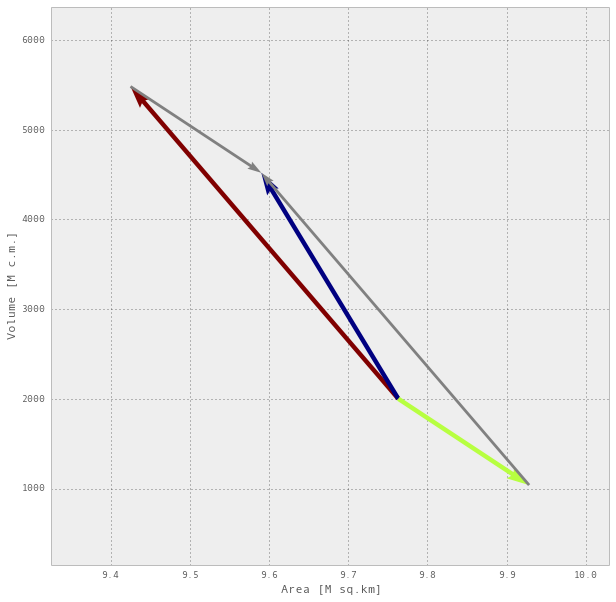

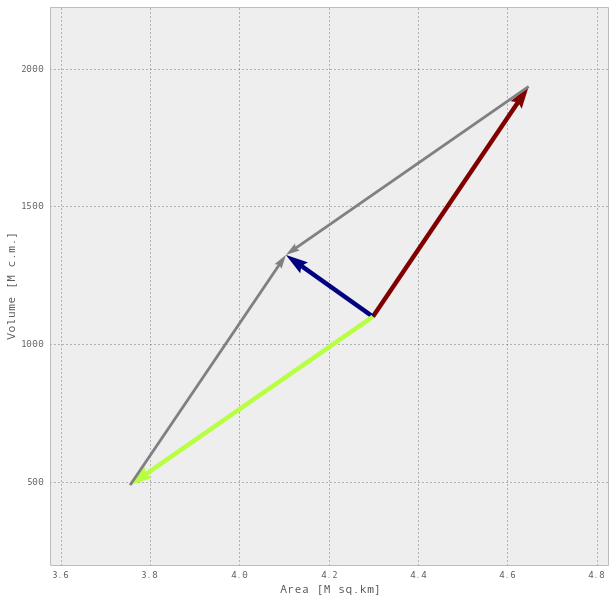

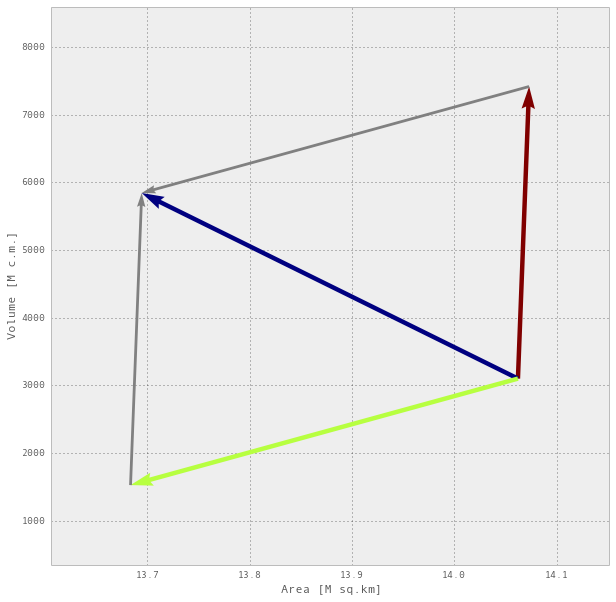

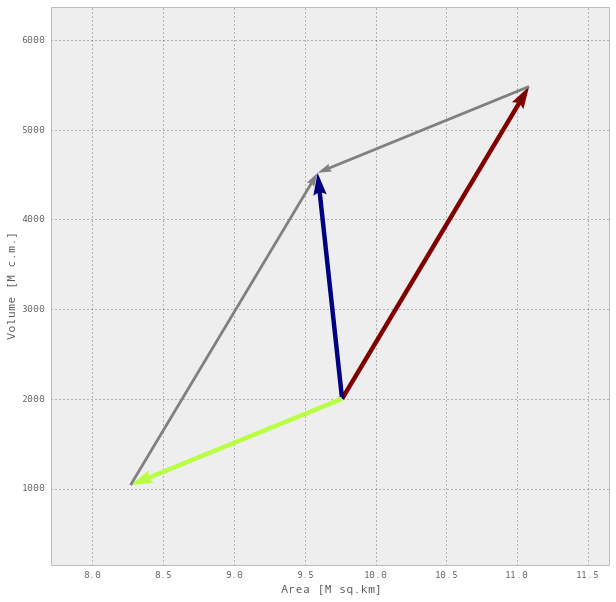

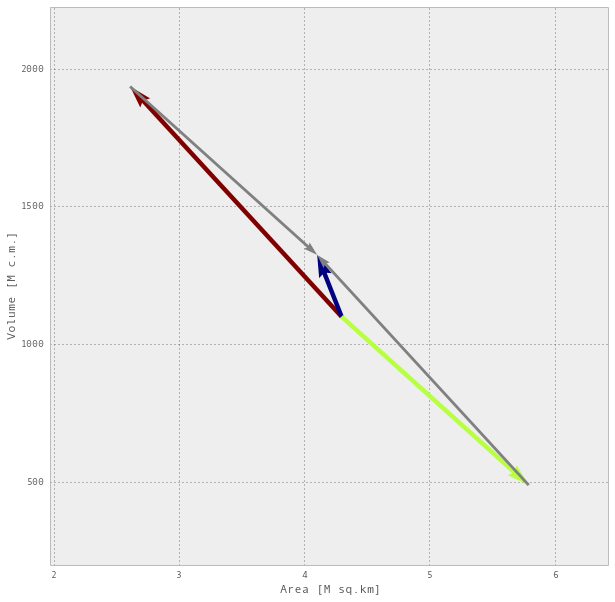

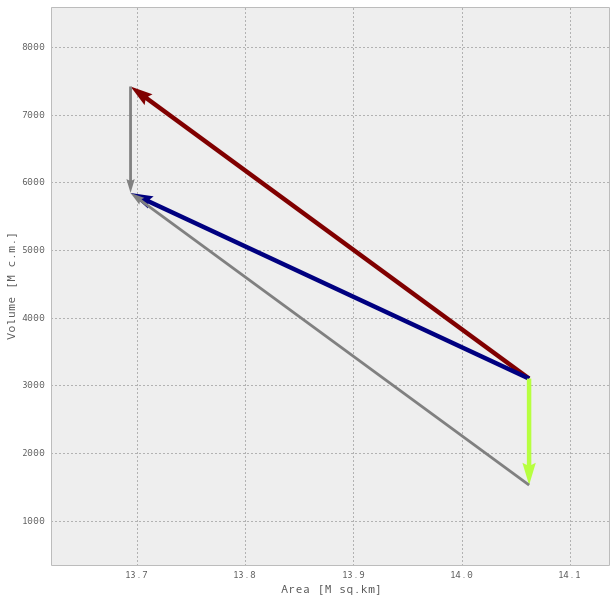

In [106]:
# Getting the values for printing the triangles
# forestDataReg:	scen 	parName 	region 	forType 	freeDim 	year 	value 	spGroup

area0 = forestDataReg[(forestDataReg['scen']=='arpege_a1b') & 
                      (forestDataReg['parName']=='forArea') &
                      (forestDataReg['year']==2015)
                     ]  # ha

#forArea_total_a1b = forArea_total[forArea_total['scen'].isin(scenarios_a1b)]

vol0  = forestDataReg[(forestDataReg['scen']=='arpege_a1b') & 
                      (forestDataReg['parName']=='vol') &
                      (forestDataReg['year']==2015)
                     ] # already in M m^3
area0_t =  area0.value.sum() / 1000000
vol0_t  =  vol0.value.sum()
area0_b =  area0[area0['spGroup']=='broadleaved'].value.sum() / 1000000
area0_c =  area0[area0['spGroup']=='coniferous'].value.sum()  / 1000000
vol0_b  =  vol0[vol0['spGroup']  =='broadleaved'].value.sum()
vol0_c  =  vol0[vol0['spGroup']  =='coniferous'].value.sum()

# scenario arpege_a1b, 2100
areat = forestDataReg[(forestDataReg['scen']=='arpege_a1b') & 
                      (forestDataReg['parName']=='forArea') &
                      (forestDataReg['year']==2100)
                     ]
volt  = forestDataReg[(forestDataReg['scen']=='arpege_a1b') & 
                      (forestDataReg['parName']=='vol') &
                      (forestDataReg['year']==2100)
                     ]
areat_t =  areat.value.sum() / 1000000
volt_t  =  volt.value.sum()
areat_b =  areat[areat['spGroup']=='broadleaved'].value.sum() / 1000000
areat_c =  areat[areat['spGroup']=='coniferous'].value.sum()  / 1000000
volt_b  =  volt[volt['spGroup']  =='broadleaved'].value.sum()
volt_c  =  volt[volt['spGroup']  =='coniferous'].value.sum()

# scenario constant, 2100
areac = forestDataReg[(forestDataReg['scen']=='constant') & 
                      (forestDataReg['parName']=='forArea') &
                      (forestDataReg['year']==2100)
                     ]
volc  = forestDataReg[(forestDataReg['scen']=='constant') & 
                      (forestDataReg['parName']=='vol') &
                      (forestDataReg['year']==2100)
                     ]
areac_t =  areac.value.sum() / 1000000
volc_t  =  volc.value.sum()
areac_b =  areac[areac['spGroup']=='broadleaved'].value.sum() / 1000000
areac_c =  areac[areac['spGroup']=='coniferous'].value.sum()  / 1000000
volc_b  =  volc[volc['spGroup']  =='broadleaved'].value.sum()
volc_c  =  volc[volc['spGroup']  =='coniferous'].value.sum()

# scenario arpege_a1b_nomgm, 2100
arean = forestDataReg[(forestDataReg['scen']=='arpege_a1b_nomgm') & 
                      (forestDataReg['parName']=='forArea') &
                      (forestDataReg['year']==2100)
                     ]
voln  = forestDataReg[(forestDataReg['scen']=='arpege_a1b_nomgm') & 
                      (forestDataReg['parName']=='vol') &
                      (forestDataReg['year']==2100)
                     ]
arean_t =  arean.value.sum() / 1000000
voln_t  =  voln.value.sum()
arean_b =  arean[arean['spGroup']=='broadleaved'].value.sum() / 1000000
arean_c =  arean[arean['spGroup']=='coniferous'].value.sum()  / 1000000
voln_b  =  voln[voln['spGroup']  =='broadleaved'].value.sum()
voln_c  =  voln[voln['spGroup']  =='coniferous'].value.sum()

print("Starting points (broad/con/tot):")
print(area0_b)
print(area0_c)
print(area0_t)
print(vol0_b)
print(vol0_c)
print(vol0_t)

print("End of the total cc vector (broad/con/tot):")
print(areat_b)
print(areat_c)
print(areat_t)
print(volt_b)
print(volt_c)
print(volt_t)

print("End of the nocc vector (broad/con/tot):")
print(areac_b)
print(areac_c)
print(areac_t)
print(volc_b)
print(volc_c)
print(volc_t)

print("End of the nomgm vector (broad/con/tot):")
print(arean_b)
print(arean_c)
print(arean_t)
print(voln_b)
print(voln_c)
print(voln_t)


print("Area/vol 2015->2100 comparition between total cc effect (scenario arpege_a1b, black), constant dynamics (including managemnt, red) and, by diff, cc effect alone (green)")
# Broadleaved triangle..
# plotVectorChart_inner(origin,end1,endt,xlabel,ylabel,filename)
parserlib.plotVectorChart_inner((area0_b,vol0_b),(areac_b,volc_b),(areat_b,volt_b),"Area [M sq.km]", "Volume [M c.m.]","charts/vector_sums/vol_area_broadL.png")
parserlib.plotVectorChart_inner((area0_c,vol0_c),(areac_c,volc_c),(areat_c,volt_c),"Area [M sq.km]", "Volume [M c.m.]","charts/vector_sums/vol_area_con.png")
parserlib.plotVectorChart_inner((area0_t,vol0_t),(areac_t,volc_t),(areat_t,volt_t),"Area [M sq.km]", "Volume [M c.m.]","charts/vector_sums/vol_area_tot.png")

print("Area/vol 2015->2100 comparition between total cc effect (scenario arpege_a1b, black), cc effect without management (red) and, by diff, management effect alone (green)")
parserlib.plotVectorChart_inner((area0_b,vol0_b),(arean_b,volc_b),(areat_b,volt_b),"Area [M sq.km]", "Volume [M c.m.]","charts/vector_sums/vol_area_broadL.png")
parserlib.plotVectorChart_inner((area0_c,vol0_c),(arean_c,volc_c),(areat_c,volt_c),"Area [M sq.km]", "Volume [M c.m.]","charts/vector_sums/vol_area_con.png")
parserlib.plotVectorChart_inner((area0_t,vol0_t),(arean_t,volc_t),(areat_t,volt_t),"Area [M sq.km]", "Volume [M c.m.]","charts/vector_sums/vol_area_tot.png")



In [99]:
"""
data = forestDataReg[(forestDataReg['scen'].isin(scenarios_a1b))        & 
                     (forestDataReg['parName'].isin(['forArea','vol'])) &
                     (forestDataReg['year'].isin([2015,2100]))
                    ].groupby(['region','parName','year','spGroup','forType']).agg(np.mean)
data.drop(['freeDim'],axis=1,inplace=True)
data.reset_index(inplace=True)
data = data.groupby(['parName','year','spGroup']).agg(np.sum)
data.drop(['region'],axis=1,inplace=True)
print(data)
area0_b = data.loc[('forArea',2015,'broadleaved')] 
area0_c = data.loc[('forArea',2015,'coniferous')] 
area0_t = area0_b + area0_c
vol0_b  = data.loc[('vol',2015,'broadleaved')] 
vol0_c  = data.loc[('vol',2015,'coniferous')] 
vol0_t  = vol0_b  + vol0_c
"""


# Broadleaved triangle..
# plotVectorChart_inner(origin,end1,endt,xlabel,ylabel,filename)
#parserlib.plotVectorChart_inner((area0_b,vol0_b),(areac_b,volc_b),(areat_b,volt_b),"Area [M sq.km]", "Volume [M c.m.]","charts/vector_sums/vol_area_broadL.png")
#parserlib.plotVectorChart_inner((area0_c,vol0_c),(areac_c,volc_c),(areat_c,volt_c),"Area [M sq.km]", "Volume [M c.m.]","charts/vector_sums/vol_area_con.png")
#parserlib.plotVectorChart_inner((area0_t,vol0_t),(areac_t,volc_t),(areat_t,volt_t),"Area [M sq.km]", "Volume [M c.m.]","charts/vector_sums/vol_area_tot.png")

"\ndata = forestDataReg[(forestDataReg['scen'].isin(scenarios_a1b))        & \n                     (forestDataReg['parName'].isin(['forArea','vol'])) &\n                     (forestDataReg['year'].isin([2015,2100]))\n                    ].groupby(['region','parName','year','spGroup','forType']).agg(np.mean)\ndata.drop(['freeDim'],axis=1,inplace=True)\ndata.reset_index(inplace=True)\ndata = data.groupby(['parName','year','spGroup']).agg(np.sum)\ndata.drop(['region'],axis=1,inplace=True)\nprint(data)\narea0_b = data.loc[('forArea',2015,'broadleaved')] \narea0_c = data.loc[('forArea',2015,'coniferous')] \narea0_t = area0_b + area0_c\nvol0_b  = data.loc[('vol',2015,'broadleaved')] \nvol0_c  = data.loc[('vol',2015,'coniferous')] \nvol0_t  = vol0_b  + vol0_c\n"